In [1]:
import os
import os.path as op
import numpy as np
import matplotlib.pyplot as plt

import hnn_core

from hnn_core import MPIBackend, JoblibBackend

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/')
from optim_utils import set_params
from hnn_core.dipole import _rmse
from hnn_core.params import _short_name

from hnn_core import new_calcium_model, simulate_dipole, jones_2009_model
import matplotlib.pyplot as plt
from hnn_core.viz import plot_dipole, plot_psd, plot_tfr_morlet
import numpy as np

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'

which_model = 'calcium'
which_setting = 'new_neymotin'

### Feedforward

In [2]:
# Feedforward model parameters

scale_factor = 30000

if which_model == 'jones':
    net = jones_2009_model()
elif which_model == 'calcium':
    net = new_calcium_model()
tstop = 1000

location = 'proximal'
burst_std = 20               # Jones 2009: input bursts variance = 400

if which_setting == 'jones':
    weights_ampa_p = {'L2_basket': 1.2e-7, 'L2_pyramidal': 0.6e-7, 'L5_pyramidal': 0.6e-7, 'L5_basket': 1.2e-7}     # max values taken from Jones 2009 for high mu; 

    syn_delays_p = {'L2_basket': 4., 'L2_pyramidal': 5, 'L5_pyramidal': 5., 'L5_basket': 4}#{'L2_basket': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1}                    # following https://modeldb.science/136803?tab=2&file=JonesEtAl2009/wiring_proc_2Dv2.hoc {'L2_basket': 4., 'L5_pyramidal': 5., 'L5_basket': 4} but this leads to no response at all
    
elif which_setting == 'neymotin':
    weights_ampa_p = {'L2_basket': 0.0, 'L2_pyramidal': 5.e-5, 'L5_pyramidal': 5.e-5, 'L5_basket': 0.0}     # max values taken from Jones 2009 for high mu; 

    
    syn_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1.}#{'L2_basket': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1} 
elif which_setting == 'hnn_core':
    weights_ampa_p = {'L2_pyramidal': 5.4e-5, 'L5_pyramidal': 5.4e-5}
    syn_delays_p = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
elif which_setting == 'new_neymotin':
    weights_ampa_p = {'L2_basket': 0.0, 'L2_pyramidal': 5.e-5, 'L5_pyramidal': 5.e-5, 'L5_basket': 0.0}     # max values taken from Jones 2009 for high mu; 

    syn_delays_p = {'L2_basket': 4., 'L2_pyramidal': 5, 'L5_pyramidal': 5., 'L5_basket': 4}

prox_seed = int(np.random.uniform(1000))
net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=prox_seed)

# with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
#     dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model)[0]

# dpl.scale(scale_factor)
# trial_idx = 0  # single trial simulated, choose the first index
# to emulate a larger patch of cortex, we can apply a simple scaling factor
# dpl.scale(scale_factor)


In [3]:


# fig, axes = plt.subplots(4, 1, constrained_layout=True, figsize=(6, 8), height_ratios=[0.5, 1, 1, 1])
# tmin, tmax = 50, 1000  # exclude the initial burn-in period from the plots


# net.cell_response.plot_spikes_hist(ax=axes[0], show=False)

# dpl.plot(tmin=tmin, tmax=tmax, color='k', ax=axes[1], show=False)
# #dpl_smooth.plot(tmin=tmin, tmax=tmax, color='r', ax=axes[1], show=False)
# axes[1].set_xlim((tmin, tmax))

# plot_psd(dpl, fmin=1., fmax=1e3, tmin=tmin, ax=axes[2], show=False)
# axes[2].set_xscale('log')

# freqs = np.arange(4, 41, 1)
# plot_tfr_morlet(dpl, freqs, n_cycles=freqs/1000 * 500, tmin=0, tmax=tmax, layer='agg', padding='zeros', ax=axes[3],
#                     colormap='inferno', colorbar=True, colorbar_inside=False, show=False)
# axes[3].set_xlim((0, 1000))
# axes[3].set_xticks(np.arange(0, 1001, 500))
# # plt.tight_layout()

# fig.savefig(os.path.join(pathfig, f'alpha_{which_model}_{which_setting}.png'), dpi=300)
# fig.savefig(os.path.join(pathfig, f'alpha_{which_model}_{which_setting}.pdf'), dpi=300)

In [8]:
x

array([[0.70292824, 0.41978685, 0.23391783, 0.09178965, 0.88132446,
        0.86488337, 0.34521286, 0.27896989, 0.43657728, 0.82870626,
        0.06012294, 0.86347758, 0.1862433 , 0.11628701, 0.84736146,
        0.95543047, 0.4882643 , 0.06165089, 0.42821221, 0.07801064],
       [0.55358382, 0.02821893, 0.4858459 , 0.7589599 , 0.81659266,
        0.45629597, 0.81091441, 0.2805668 , 0.47555273, 0.32345168,
        0.3871732 , 0.01246255, 0.43798229, 0.37470706, 0.32421648,
        0.62751489, 0.54306484, 0.69035679, 0.49312223, 0.46819112],
       [0.98498854, 0.49548649, 0.18306364, 0.26476279, 0.15279578,
        0.64760609, 0.72033522, 0.01282213, 0.87281267, 0.82445023,
        0.36676242, 0.71282925, 0.06868298, 0.34924701, 0.92065492,
        0.45734671, 0.51575347, 0.74938473, 0.17794207, 0.43833957]])

### Feedback

In [4]:
location = 'distal'
burst_std = 20              # I believe the std was the same for FB and FF inputs in Jones 2009

if which_setting == 'jones':
    weights_ampa_d = {'L2_basket': 1.2e-7*4, 'L5_pyramidal': 0.6e-7*4, 'L2_pyramidal': 0.6e-7*4}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
    syn_delays_d = {'L2_basket': 4, 'L5_pyramidal': 5., 'L2_pyramidal': 5.}
    delay = 3
elif which_setting == 'neymotin':
    weights_ampa_d = {'L2_basket': 0, 'L5_pyramidal': 5.e-5, 'L2_pyramidal': 5.e-5}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
    syn_delays_d = {'L2_basket': 5, 'L5_pyramidal': 5., 'L2_pyramidal': 5.}
    delay = 0
elif which_setting == 'hnn_core':
    delay = 0
    burst_std = 15
    weights_ampa_d = {'L2_pyramidal': 5.4e-5, 'L5_pyramidal': 5.4e-5}
    syn_delays_d = {'L2_pyramidal': 5., 'L5_pyramidal': 5.}
elif which_setting == 'new_neymotin':
    weights_ampa_d = {'L2_basket': 0, 'L5_pyramidal': 5.e-5*4, 'L2_pyramidal': 5.e-5*4}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
    syn_delays_d = {'L2_basket': 5, 'L5_pyramidal': 5., 'L2_pyramidal': 5.}
    delay = 0

dist_seed = int(np.random.uniform(1000))

net.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=dist_seed)




In [5]:
with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model)[0]
dpl.scale(scale_factor)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

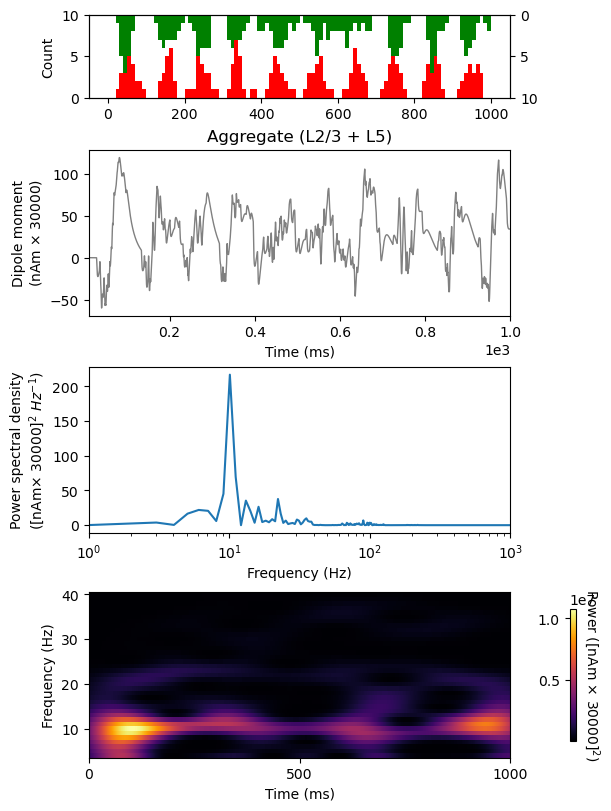

In [7]:
import numpy as np

fig, axes = plt.subplots(4, 1, constrained_layout=True, figsize=(6, 8), height_ratios=[0.5, 1, 1, 1])
tmin, tmax = 10, 1000  # exclude the initial burn-in period from the plots

bins = np.arange(0, 1010, 10)  # histogram bins
# We'll make a copy of the dipole before smoothing in order to compare
# window_len = 10  # convolve with a 10 ms-long Hamming window
# dpl_smooth = dpl.copy().smooth(window_len)

# proximal and distal histogram
spike_prox = np.array(net.cell_response.spike_times_by_type['alpha_prox']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['alpha_dist']).reshape(-1,1)

axes[0].hist(spike_prox, bins, color='r')
axes[0].set_ylim([0, 10])
axes[0].set_ylabel('Count')
ax1tw = axes[0].twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 10])
ax1tw.invert_yaxis()

dpl.plot(tmin=tmin, tmax=tmax, color='k', ax=axes[1], show=False)
axes[1].set_xlim((tmin, tmax))

plot_psd(dpl, fmin=1., fmax=1e3, tmin=tmin, ax=axes[2], show=False)
axes[2].set_xscale('log')

freqs = np.arange(4, 41, 1)
plot_tfr_morlet(dpl, freqs, n_cycles=freqs/1000 * 500, tmin=0, tmax=tmax, layer='agg', padding='zeros', ax=axes[3],
                    colormap='inferno', colorbar=True, colorbar_inside=False, show=False)
axes[3].set_xlim((0, 1000))
axes[3].set_xticks(np.arange(0, 1001, 500))

fig.savefig(os.path.join(pathfig, f'alpha_beta_complex_{which_model}_{which_setting}_no_delay.png'), dpi=300)


In [ ]:
# try different settings
if which_model == 'jones':
    net = jones_2009_model()
elif which_model == 'calcium':
    net = new_calcium_model()


net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location='proximal',
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p)
net.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location='distal',
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d)

with JoblibBackend(n_jobs=10):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=10, bsl_cor=which_model)

In [ ]:
fig, ax = plt.subplots()
plot_psd(dpl, fmin=1., fmax=1e3, tmin=tmin, ax = ax, show=False)
ax.set_xscale('log')

fig.savefig(os.path.join(pathfig, f'alpha_beta_complex_{which_model}_{which_setting}_adjust_delay_10trials.png'), dpi=300)
fig.savefig(os.path.join(pathfig, f'alpha_beta_complex_{which_model}_{which_setting}_adjust_delay_10trials.pdf'), dpi=300)

## Symmetry index

In [ ]:
dt = np.diff(dpl.times)[0]
fs = 1000/dt

In [ ]:
# symmetry index

from scipy.signal import butter, lfilter, find_peaks

def butter_bandpass(lowcut, highcut, fs, order=5):
        nyq = 0.5 * fs
        low = lowcut / nyq
        high = highcut / nyq
        b, a = butter(order, [low, high], btype='band')
        return b, a


def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = lfilter(b, a, data)
    return y

def symmetry_index(dpl, lowcut=7, highcut=29, show_plot=False):

    cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
        
    filt_dpl = butter_bandpass_filter(dpl.data['agg'], lowcut, highcut, fs, order=2)
    peaks, _ = find_peaks(filt_dpl, prominence=0.01)
    troughs, _ = find_peaks(-filt_dpl, prominence=0.01)

    if len(peaks) == len(troughs):
        if troughs[0] < peaks[0]:
            sind = (np.abs(filt_dpl[peaks[:-1]]) - np.abs(filt_dpl[troughs[1:]]))/(np.abs(filt_dpl[peaks[:-1]]) + np.abs(filt_dpl[troughs[1:]]))
        else:
            sind = (np.abs(filt_dpl[peaks]) - np.abs(filt_dpl[troughs]))/(np.abs(filt_dpl[peaks]) + np.abs(filt_dpl[troughs]))
    elif len(peaks) > len(troughs):
         sind = (np.abs(filt_dpl[peaks[int(len(peaks)-len(troughs)):]]) - np.abs(filt_dpl[troughs]))/(np.abs(filt_dpl[peaks[int(len(peaks)-len(troughs)):]]) + np.abs(filt_dpl[troughs]))
    elif len(peaks) < len(troughs):

        peak_diff = int(len(troughs)-len(peaks))
        if troughs[0] < peaks[0]:
            sind = (np.abs(filt_dpl[peaks]) - np.abs(filt_dpl[troughs[peak_diff:]]))/(np.abs(filt_dpl[peaks]) + np.abs(filt_dpl[troughs[peak_diff:]]))
        else:
            sind = (np.abs(filt_dpl[peaks]) - np.abs(filt_dpl[troughs[:-peak_diff]]))/(np.abs(filt_dpl[peaks]) + np.abs(filt_dpl[troughs[:-peak_diff]]))
         

    if show_plot:

        fig, ax = plt.subplots(1, 1, figsize=(7, 5))
        ax.plot(dpl.times, dpl.data['agg'], label='raw', color=cols[0])
        ax.plot(dpl.times, filt_dpl, label='filtered', color=cols[1])
        ax.plot(dpl.times[peaks], filt_dpl[peaks], 'x', label='peaks', color=cols[2])
        ax.plot(dpl.times[troughs], filt_dpl[troughs], 'x', label='troughs', color=cols[3])
        ax.set_xlabel('time (ms)')
        ax.set_ylabel('dipole (nAm)')
        ax.legend()

        fig.savefig(os.path.join(pathfig, f'symmetry_index_{which_model}_{which_setting}.png'), dpi=300)
        fig.savefig(os.path.join(pathfig, f'symmetry_index_{which_model}_{which_setting}.pdf'), dpi=300)

    return sind


In [ ]:
sind = symmetry_index(dpl, lowcut=7, highcut=29, show_plot=True)


In [ ]:
# symmetry index for over 10 trials
from hnn_core import JoblibBackend

if which_model == 'jones':
    net = jones_2009_model()
elif which_model == 'calcium':
    net = new_calcium_model()

tstop = 1000

location = 'proximal'
burst_std = 20               # Jones 2009: input bursts variance = 400

net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p)

net.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d)

with JoblibBackend(n_jobs=10):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=10, bsl_cor=which_model)



In [ ]:
sind = np.array(())

for i,trl in enumerate(dpl):
    trl.scale(scale_factor)
    sind = np.append(sind, symmetry_index(trl, lowcut=7, highcut=29, show_plot=False))

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.hist(sind, bins=20)
ax.set_xlabel('symmetry index')
ax.set_ylabel('Count')
ax.plot(np.ones(50,)*np.median(sind), np.linspace(0,30), 'k', label='mean', linestyle='--')  
ax.set_xticks(np.arange(-1, 1.1, 0.5))
ax.set_yticks(np.arange(0, 31, 10))
fig.savefig(os.path.join(pathfig, f'symmetry_index_10_trials_{which_model}_{which_setting}.png'), dpi=300)
fig.savefig(os.path.join(pathfig, f'symmetry_index_10_trials_{which_model}_{which_setting}.pdf'), dpi=300)

In [ ]:
# Delay between proximal and distal input -> alpha/beta ratio?
from scipy.signal import periodogram
import pickle
delays = np.arange(0, 96, 5)
alpha_beta_ratio = np.zeros(len(delays))
for i, delay in enumerate(delays):

    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = new_calcium_model()
    tstop = 1000

    burst_std = 20               # Jones 2009: input bursts variance = 400

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model)[0]

    freqs, Pxx = periodogram(dpl.data['agg'], dpl.sfreq, window='hamming', nfft=len(dpl.data['agg']))

    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio[i] = beta_pow/alpha_pow

delay_ratio = dict()
delay_ratio['delay'] = delays
delay_ratio['alpha_beta_ratio'] = alpha_beta_ratio

with open(f'delay_ratio_{which_model}_{which_setting}.pkl', 'wb') as f:
    pickle.dump(delay_ratio, f)

In [ ]:
# Variance of drive on alpha beta ratio
from scipy.signal import periodogram
burst_std = np.arange(np.sqrt(200), np.sqrt(600), 2)
alpha_beta_ratio_prox_std = np.zeros(len(burst_std))
for i, bstd in enumerate(burst_std):

    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = new_calcium_model()
    tstop = 1000

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=bstd, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+5, burst_rate=10, burst_std=20, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model)[0]

    freqs, Pxx = periodogram(dpl.data['agg'], dpl.sfreq, window='hamming', nfft=len(dpl.data['agg']))

    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio_prox_std[i] = beta_pow/alpha_pow

# vary alpha variance
alpha_beta_ratio_dist_std = np.zeros(len(burst_std))
for i, bstd in enumerate(burst_std):
    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = new_calcium_model()
    tstop = 1000

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=20, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+5, burst_rate=10, burst_std=bstd, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model)[0]

    freqs, Pxx = periodogram(dpl.data['agg'], dpl.sfreq, window='hamming', nfft=len(dpl.data['agg']))

    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio_dist_std[i] = beta_pow/alpha_pow

burst_std_ratio = dict()
burst_std_ratio['burst_std'] = burst_std
burst_std_ratio['alpha_beta_ratio_prox'] = alpha_beta_ratio_prox_std
burst_std_ratio['alpha_beta_ratio_dist'] = alpha_beta_ratio_dist_std


In [ ]:
import pickle
with open(f'burst_std_ratio_{which_model}_{which_setting}.pkl', 'wb') as f:
    pickle.dump(burst_std_ratio, f)

In [ ]:
# vary amplitude (number of cells)

num_cells = np.arange(5, 15, 1)
alpha_beta_ratio_num_cells_dist = np.zeros(len(num_cells))
for i, n_cells in enumerate(num_cells):
    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = new_calcium_model()
    tstop = 1000

    burst_std = 20               # Jones 2009: input bursts variance = 400

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+5, burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=int(n_cells), location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model)[0]

    freqs, Pxx = periodogram(dpl.data['agg'], dpl.sfreq, window='hamming', nfft=len(dpl.data['agg']))

    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio_num_cells_dist[i] = beta_pow/alpha_pow

alpha_beta_ratio_num_cells_prox = np.zeros(len(num_cells))
for i, n_cells in enumerate(num_cells):
    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = new_calcium_model()
    tstop = 1000

    burst_std = 20               # Jones 2009: input bursts variance = 400

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=int(n_cells), location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+5, burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model)[0]

    freqs, Pxx = periodogram(dpl.data['agg'], dpl.sfreq, window='hamming', nfft=len(dpl.data['agg']))

    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio_num_cells_prox[i] = beta_pow/alpha_pow

num_cells_ratio = dict()
num_cells_ratio['num_cells'] = num_cells
num_cells_ratio['alpha_beta_ratio_prox'] = alpha_beta_ratio_num_cells_prox
num_cells_ratio['alpha_beta_ratio_dist'] = alpha_beta_ratio_num_cells_dist
with open(f'num_cells_ratio_{which_model}_{which_setting}.pkl', 'wb') as f:
    pickle.dump(num_cells_ratio, f)

In [ ]:
with open(f'delay_ratio_{which_model}_{which_setting}.pkl', 'rb') as f:
    delay_ratio = pickle.load(f)

fig, ax = plt.subplots(3, 1, figsize=(4, 12))
ax[0].plot(delay_ratio['delay'], delay_ratio['alpha_beta_ratio'], 'k', linewidth=2)
ax[0].set_xlabel('delay (ms)')
ax[0].set_ylabel('beta/alpha ratio')
ax[0].set_xticks(np.arange(5, 91, 15))


with open(f'burst_std_ratio_{which_model}_{which_setting}.pkl', 'rb') as f:
   burst_std_ratio = pickle.load(f)
   
ax[1].plot(burst_std_ratio['burst_std'], burst_std_ratio['alpha_beta_ratio_prox'], 'tab:red', label='vary FF', linewidth=2)
ax[1].plot(burst_std_ratio['burst_std'], burst_std_ratio['alpha_beta_ratio_dist'], 'tab:blue', label='vary FB', linewidth=2)


with open(f'num_cells_ratio_{which_model}_{which_setting}.pkl', 'rb') as f:
    num_cells_ratio = pickle.load(f)

ax[2].plot(num_cells_ratio['num_cells'], num_cells_ratio['alpha_beta_ratio_prox'], 'tab:red', label='vary FF', linewidth=2)
ax[2].plot(num_cells_ratio['num_cells'], num_cells_ratio['alpha_beta_ratio_dist'], 'tab:blue', label='vary FB', linewidth=2)
ax[2].set_xlabel('number of cells')
ax[1].set_xlabel('burst std')

for a in ax:
    a.set_ylabel('beta/alpha ratio')

fig.savefig(os.path.join(pathfig, f'alpha_beta_ratio_{which_model}_{which_setting}.png'), dpi=300)
fig.savefig(os.path.join(pathfig, f'alpha_beta_ratio_{which_model}_{which_setting}.pdf'), dpi=300)